# Capstone: Inside the Backward Pass

A small neural network library built from scratch with **NumPy and Matplotlib only**.

| Phase | What we do |
|---|---|
| Dataset | Generate the two moons dataset with NumPy |
| Phase 2 | Build the engine: `Linear`, `Sigmoid`, `ReLU`, `Tanh`, `MSELoss`, `BCELoss`, `Network` |
| Phase 1 | Run the tiny paper network through the code and compare with the hand calculation |
| Phase 3 | `gradient_check()`: numerical vs backprop gradients |
| Final | Train on two moons: linear model vs hidden-layer network |

In [24]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

## 1. Dataset: two moons

`X` has shape `(N, 2)`: each row is a point `(x1, x2)`.
`y` has shape `(N, 1)`: the target, 0 for the upper moon and 1 for the lower moon.
A straight line cannot separate the two classes.

X shape: (300, 2)   y shape: (300, 1)


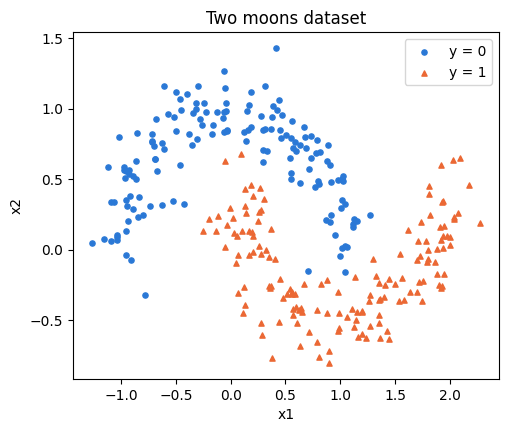

In [25]:
def make_moons(n=300, noise=0.15, seed=42):
    rng = np.random.default_rng(seed)
    n0 = n // 2
    n1 = n - n0

    t0 = np.linspace(0, np.pi, n0)
    t1 = np.linspace(0, np.pi, n1)

    upper = np.stack([np.cos(t0), np.sin(t0)], axis=1)              # class 0
    lower = np.stack([1 - np.cos(t1), 0.5 - np.sin(t1)], axis=1)    # class 1

    X = np.vstack([upper, lower]) + rng.normal(0, noise, size=(n, 2))
    y = np.concatenate([np.zeros(n0), np.ones(n1)]).reshape(-1, 1)

    order = rng.permutation(n)
    return X[order], y[order]


X, y = make_moons(n=300, noise=0.15, seed=42)
print("X shape:", X.shape, "  y shape:", y.shape)

plt.figure(figsize=(5.5, 4.5))
plt.scatter(X[y[:, 0] == 0, 0], X[y[:, 0] == 0, 1], c="#2a78d6", s=14, label="y = 0")
plt.scatter(X[y[:, 0] == 1, 0], X[y[:, 0] == 1, 1], c="#eb6834", s=14, marker="^", label="y = 1")
plt.title("Two moons dataset")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.show()

## 2. The engine

Every layer has `forward(x)` and `backward(upstream_grad)`.
Batch convention: `x` has shape `(N, features)`.

### Linear layer
`z = x Wᵀ + b`, with `W` of shape `(out, in)` so `W[i][j]` is the weight from input `j` to neuron `i`.

Backward rules (the heart of backprop):
- `dW = upstreamᵀ · x`
- `db = sum(upstream)`

In [26]:
class Linear:
    def __init__(self, n_in, n_out, rng=None):
        rng = rng or np.random.default_rng(0)
        self.W = rng.normal(0, 1 / np.sqrt(n_in), size=(n_out, n_in))
        self.b = np.zeros(n_out)
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)

    def forward(self, x):
        self.x = x                       # store the input, backward needs it
        return x @ self.W.T + self.b

    def backward(self, upstream):
        self.dW = upstream.T @ self.x
        self.db = upstream.sum(axis=0)
        return upstream @ self.W         # gradient for the layer input

### Activations
Each one stores what it needs in `forward` and multiplies the upstream gradient by its derivative in `backward`.

| Activation | Derivative used in `backward` |
|---|---|
| Sigmoid | `s(1 - s)` |
| ReLU | `1` if `z > 0`, else `0` |
| Tanh | `1 - tanh(z)²` |

In [27]:
class Sigmoid:
    def forward(self, x):
        self.x = x
        self.out = 1.0 / (1.0 + np.exp(-x))
        return self.out

    def backward(self, upstream):
        return upstream * self.out * (1 - self.out)


class ReLU:
    def forward(self, x):
        self.x = x
        self.out = np.maximum(0, x)
        return self.out

    def backward(self, upstream):
        return upstream * (self.x > 0)


class Tanh:
    def forward(self, x):
        self.x = x
        self.out = np.tanh(x)
        return self.out

    def backward(self, upstream):
        return upstream * (1 - self.out ** 2)

### Losses
- **MSELoss**: `L = 1/(2m) · Σ (ŷ − y)²`. For one data point this is `½(ŷ − y)²`, the formula on the paper.
- **BCELoss**: `L = −1/m · Σ [ y·log(ŷ) + (1−y)·log(1−ŷ) ]`

Their `backward()` has no input: it starts the chain with `dL/dŷ`.

In [28]:
class MSELoss:
    def forward(self, y_hat, y):
        self.y_hat, self.y = y_hat, y
        return np.sum((y_hat - y) ** 2) / (2 * y.shape[0])

    def backward(self):
        return (self.y_hat - self.y) / self.y.shape[0]


class BCELoss:
    EPS = 1e-12                                   # avoids log(0)

    def forward(self, y_hat, y):
        self.y_hat = np.clip(y_hat, self.EPS, 1 - self.EPS)
        self.y = y
        m = y.shape[0]
        return -np.sum(y * np.log(self.y_hat) + (1 - y) * np.log(1 - self.y_hat)) / m

    def backward(self):
        m = self.y.shape[0]
        return (self.y_hat - self.y) / (self.y_hat * (1 - self.y_hat)) / m

### Network
- `forward`: calls the layers **in order**
- `backward`: calls the layers **in reverse order**, passing each result to the next one
- `grad_trace[i]` keeps the gradient that enters layer `i`, so we can compare every step with the paper

In [29]:
class Network:
    def __init__(self, layers):
        self.layers = layers

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, grad):
        self.grad_trace = []
        for layer in reversed(self.layers):
            self.grad_trace.append(grad)
            grad = layer.backward(grad)
        self.grad_trace.reverse()                 # index i = layer i
        return grad                               # dL/d(network input)

    def step(self, lr):
        for layer in self.layers:
            if isinstance(layer, Linear):
                layer.W -= lr * layer.dW
                layer.b -= lr * layer.db

    def predict(self, x):
        return (self.forward(x) >= 0.5).astype(int)

## 3. Phase 1 network through the code

Network: **2 inputs → 2 hidden (sigmoid) → 1 output (sigmoid)**, MSE loss, one data point.

> **Replace the numbers below with the ones from your teacher / your paper.**
> The printed values must match your hand calculation (to about 6 decimals).
> If they do not, check: rounding, the loss definition (`½` or not), and whether the output has a sigmoid.

In [30]:
def build_phase1_network():
    l1 = Linear(2, 2)
    l1.W = np.array([[0.1, 0.2],      # W11  W12
                     [0.3, 0.4]])     # W21  W22
    l1.b = np.array([0.1, 0.1])       # b1   b2

    l2 = Linear(2, 1)
    l2.W = np.array([[0.6, 0.7]])     # W31  W32
    l2.b = np.array([0.1])            # b3

    return Network([l1, Sigmoid(), l2, Sigmoid()])


x_p1 = np.array([[1.0, 0.5]])         # x1, x2
y_p1 = np.array([[1.0]])

net_p1 = build_phase1_network()
loss_p1 = MSELoss()

y_hat = net_p1.forward(x_p1)
loss = loss_p1.forward(y_hat, y_p1)
dx = net_p1.backward(loss_p1.backward())

l1, s1, l2, s2 = net_p1.layers

In [31]:
print("--- forward ---")
print("z1, z2           =", s1.x.ravel())
print("h1, h2           =", s1.out.ravel())
print("z3               =", s2.x.ravel())
print("y_hat            =", y_hat.ravel())
print("loss             =", round(float(loss), 6))

print("\n--- backward ---")
print("dL/dy_hat        =", net_p1.grad_trace[3].ravel())
print("dL/dz3           =", net_p1.grad_trace[2].ravel())
print("dL/dW31, dL/dW32 =", l2.dW.ravel())
print("dL/db3           =", l2.db.ravel())
print("dL/dh1, dL/dh2   =", net_p1.grad_trace[1].ravel())
print("dL/dz1, dL/dz2   =", net_p1.grad_trace[0].ravel())
print("dL/dW1 (row 1 = neuron 1, row 2 = neuron 2):")
print(l1.dW)
print("dL/db1, dL/db2   =", l1.db)

--- forward ---
z1, z2           = [0.3 0.6]
h1, h2           = [0.574443 0.645656]
z3               = [0.896625]
y_hat            = [0.710255]
loss             = 0.041976

--- backward ---
dL/dy_hat        = [-0.289745]
dL/dz3           = [-0.059627]
dL/dW31, dL/dW32 = [-0.034252 -0.038499]
dL/db3           = [-0.059627]
dL/dh1, dL/dh2   = [-0.035776 -0.041739]
dL/dz1, dL/dz2   = [-0.008746 -0.009549]
dL/dW1 (row 1 = neuron 1, row 2 = neuron 2):
[[-0.008746 -0.004373]
 [-0.009549 -0.004775]]
dL/db1, dL/db2   = [-0.008746 -0.009549]


## 4. Training on two moons

We train two models on the same data:
1. **Linear model** (`Linear` + `Sigmoid`): no hidden layer, so it can only draw a straight line.
2. **Hidden-layer network** (2 → 8 Tanh → 1 Sigmoid).

Both use `BCELoss` and plain gradient descent. We keep 75% of the points for training and 25% for testing.

In [37]:
n_train = 225
X_train, y_train = X[:n_train], y[:n_train]
X_test,  y_test  = X[n_train:], y[n_train:]


def train(net, loss_fn, X, y, lr=0.5, epochs=3000, print_every=500):
    history = []
    for epoch in range(1, epochs + 1):
        y_hat = net.forward(X)
        loss = loss_fn.forward(y_hat, y)
        net.backward(loss_fn.backward())
        net.step(lr)
        history.append(loss)
        if epoch % print_every == 0:
            acc = np.mean(net.predict(X) == y)
            print(f"  epoch {epoch:5d}   loss {loss:.4f}   accuracy {acc:.3f}")
    return history

In [38]:
print("Linear model (Linear + Sigmoid):")
rng = np.random.default_rng(0)
linear_net = Network([Linear(2, 1, rng), Sigmoid()])
hist_linear = train(linear_net, BCELoss(), X_train, y_train)
acc_linear = np.mean(linear_net.predict(X_test) == y_test)
print(f"  TEST accuracy: {acc_linear:.3f}\n")

print("Network 2 -> 8 (Tanh) -> 1 (Sigmoid):")
rng = np.random.default_rng(0)
hidden_net = Network([Linear(2, 8, rng), Tanh(), Linear(8, 1, rng), Sigmoid()])
hist_hidden = train(hidden_net, BCELoss(), X_train, y_train)
acc_hidden = np.mean(hidden_net.predict(X_test) == y_test)
print(f"  TEST accuracy: {acc_hidden:.3f}")

Linear model (Linear + Sigmoid):
  epoch   500   loss 0.2754   accuracy 0.867
  epoch  1000   loss 0.2748   accuracy 0.871
  epoch  1500   loss 0.2748   accuracy 0.871
  epoch  2000   loss 0.2748   accuracy 0.871
  epoch  2500   loss 0.2748   accuracy 0.871
  epoch  3000   loss 0.2748   accuracy 0.871
  TEST accuracy: 0.893

Network 2 -> 8 (Tanh) -> 1 (Sigmoid):
  epoch   500   loss 0.0856   accuracy 0.973
  epoch  1000   loss 0.0391   accuracy 0.991
  epoch  1500   loss 0.0283   accuracy 0.987
  epoch  2000   loss 0.0238   accuracy 0.987
  epoch  2500   loss 0.0213   accuracy 0.987
  epoch  3000   loss 0.0197   accuracy 0.987
  TEST accuracy: 1.000


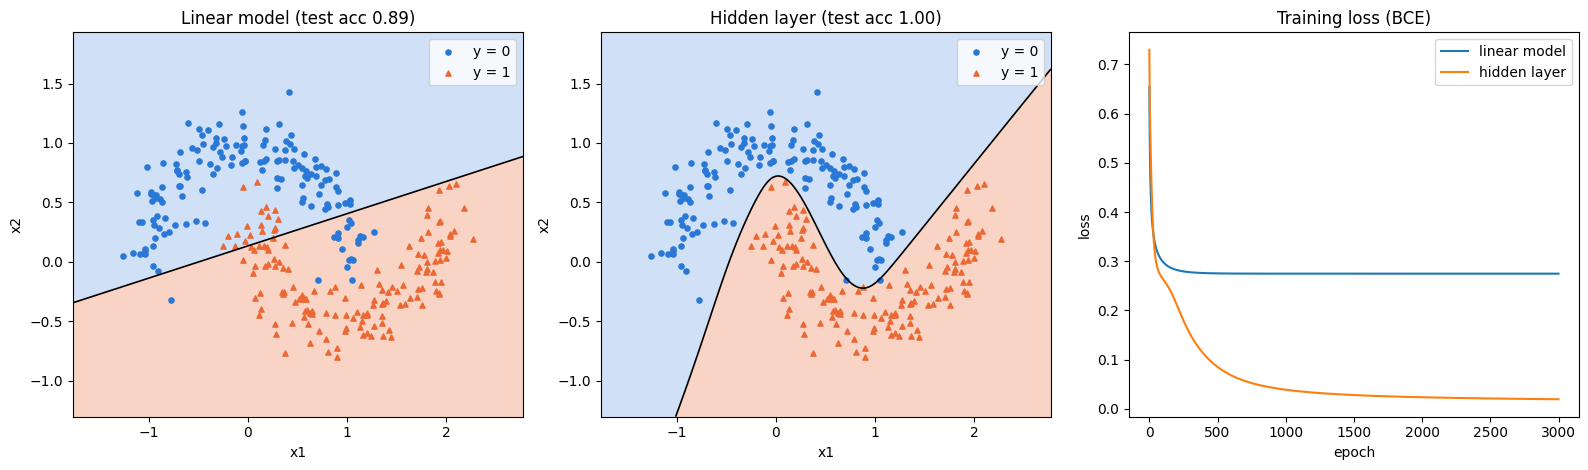

In [39]:
def plot_boundary(ax, net, X, y, title):
    pad = 0.5
    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
        np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300),
    )
    zz = net.forward(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[0, 0.5, 1], colors=["#cfe0f7", "#f9d3c3"])
    ax.contour(xx, yy, zz, levels=[0.5], colors="black", linewidths=1.2)
    ax.scatter(X[y[:, 0] == 0, 0], X[y[:, 0] == 0, 1], c="#2a78d6", s=14, label="y = 0")
    ax.scatter(X[y[:, 0] == 1, 0], X[y[:, 0] == 1, 1], c="#eb6834", s=14, marker="^", label="y = 1")
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend(loc="upper right")


fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
plot_boundary(axes[0], linear_net, X, y, f"Linear model (test acc {acc_linear:.2f})")
plot_boundary(axes[1], hidden_net, X, y, f"Hidden layer (test acc {acc_hidden:.2f})")
axes[2].plot(hist_linear, label="linear model")
axes[2].plot(hist_hidden, label="hidden layer")
axes[2].set_title("Training loss (BCE)")
axes[2].set_xlabel("epoch")
axes[2].set_ylabel("loss")
axes[2].legend()
plt.tight_layout()
plt.show()

## 6. Summary for the report

- The backward pass is the chain rule applied layer by layer, in reverse order.
- Each layer only needs two things: what it stored in `forward`, and the gradient coming from the layer after it.
- `Linear`: `dW = upstreamᵀ · x`, `db = sum(upstream)`
- The linear model stays around 87–89% on two moons because a line cannot follow the curved boundary; the hidden layer learns it.